# MLE, MAP, and Statistical Origins of Loss Functions

**AI Mathematics · 3. Probability and Statistics**

Derive common loss functions from probability models and connect Bayesian priors to regularization.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Understand likelihood and log-likelihood.
- Derive MSE from a Gaussian noise model and cross-entropy from Bernoulli labels.
- Connect MAP estimation with L1/L2 penalties.

In [1]:
import numpy as np

## 1. Maximum likelihood estimation (MLE)
Given independent observations \(y_i\) and model parameters \(\theta\), MLE maximizes \(p(y|\theta)\), or equivalently the log-likelihood. Logarithms convert products into sums and often improve numerical stability.

In [2]:
import numpy as np

y = np.array([1.0, 1.2, 0.9, 1.1, 0.8])
# For a Gaussian with known sigma, the MLE of the mean is the sample mean.
mu_mle = y.mean()
print("MLE mean:", mu_mle)

MLE mean: 1.0


## 2. MSE from Gaussian noise
Assume \(y_i=f_\theta(x_i)+\epsilon_i\), where \(\epsilon_i\sim\mathcal{N}(0,\sigma^2)\). The negative log-likelihood, ignoring constants and fixed scale, is proportional to \(\sum_i(y_i-f_\theta(x_i))^2\). Thus squared-error loss corresponds to Gaussian observation noise.

In [3]:
y_true = np.array([1.0, 2.0, 3.0])
y_pred = np.array([0.8, 2.2, 2.7])
mse = np.mean((y_true - y_pred)**2)
print("MSE:", mse)

# Gaussian negative log-likelihood includes a scale term if sigma is learned.
sigma = 0.5
nll = np.mean(0.5*((y_true-y_pred)/sigma)**2 + np.log(sigma))
print("Gaussian NLL up to a constant:", nll)

MSE: 0.05666666666666664
Gaussian NLL up to a constant: -0.579813847226612


## 3. Cross-entropy from Bernoulli likelihood
For a binary target \(y\in\{0,1\}\) and predicted probability \(p\), negative log-likelihood is \(-[y\log p+(1-y)\log(1-p)]\). In code, clip probabilities away from 0 and 1 to avoid taking logarithms of zero; production implementations typically use numerically stable logits-based formulas.

In [4]:
def binary_cross_entropy(y, p, eps=1e-12):
    y = np.asarray(y, dtype=float)
    p = np.clip(np.asarray(p, dtype=float), eps, 1-eps)
    return -np.mean(y*np.log(p) + (1-y)*np.log(1-p))

y = np.array([1, 0, 1, 1])
p = np.array([0.9, 0.2, 0.6, 0.8])
print("binary cross-entropy:", binary_cross_entropy(y, p))
print("bad confident prediction cost:", binary_cross_entropy([1], [1e-8]))

binary cross-entropy: 0.2656183105130591
bad confident prediction cost: 18.420680743952367


## 4. Maximum a posteriori (MAP) and regularization
MAP maximizes \(p(\theta|y)\propto p(y|\theta)p(\theta)\). Taking negative logarithms gives a data-fit term plus a prior penalty. A zero-mean Gaussian prior on weights yields an L2 penalty; a Laplace prior yields an L1 penalty (up to scaling constants). The exact coefficients depend on the assumed variance, prior scale, and loss normalization.

In [5]:
w = np.array([0.5, -1.0, 2.0])
data_loss = 1.2
lambda_l2 = 0.1
lambda_l1 = 0.1
objective_l2 = data_loss + lambda_l2 * np.sum(w**2)
objective_l1 = data_loss + lambda_l1 * np.sum(np.abs(w))
print("L2-regularized objective:", objective_l2)
print("L1-regularized objective:", objective_l1)

L2-regularized objective: 1.725
L1-regularized objective: 1.55


## 5. Softmax cross-entropy
For a multiclass label, the softmax maps logits to a probability distribution. Cross-entropy is the negative log probability assigned to the correct class. Use log-sum-exp stabilization for large logits.

In [6]:
logits = np.array([2.0, 1.0, -1.0])
shifted = logits - logits.max()
probs = np.exp(shifted) / np.exp(shifted).sum()
true_class = 0
loss = -np.log(probs[true_class])
print("probabilities:", probs)
print("cross-entropy:", loss)

probabilities: [0.70538451 0.25949646 0.03511903]
cross-entropy: 0.34901221676818633


### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Practical lab: likelihood, cross-entropy, and regularization

Maximum likelihood chooses the parameter that makes the observed data most probable. Minimizing negative log-likelihood is equivalent to maximizing likelihood because the negative logarithm reverses the ordering. For Bernoulli observations, this leads directly to binary cross-entropy.

sample proportion / MLE: 0.7


12_mle_map_and_loss_functions.ipynb:cell15:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


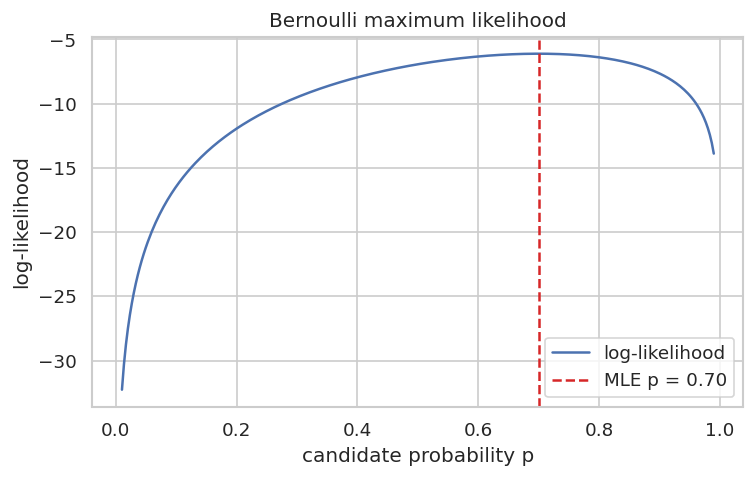

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_mle_observed = np.array([1, 1, 0, 1, 0, 1, 1, 1, 0, 1])
viz_mle_p = np.linspace(0.01, 0.99, 300)
viz_mle_loglik = (viz_mle_observed.sum()*np.log(viz_mle_p) + (len(viz_mle_observed)-viz_mle_observed.sum())*np.log(1-viz_mle_p))
viz_mle_nll = -viz_mle_loglik
viz_mle_hat = viz_mle_observed.mean()
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(viz_mle_p, viz_mle_loglik, label="log-likelihood")
ax.axvline(viz_mle_hat, color="tab:red", linestyle="--", label=f"MLE p = {viz_mle_hat:.2f}")
ax.set_xlabel("candidate probability p"); ax.set_ylabel("log-likelihood"); ax.legend(); ax.set_title("Bernoulli maximum likelihood"); plt.show()
print("sample proportion / MLE:", viz_mle_hat)

### Visualize the regularization trade-off

Regularization adds a penalty to the data-fitting loss. L2 regularization discourages large coefficients smoothly, while L1 regularization can drive some coefficients exactly to zero. The following plot is illustrative: its purpose is to show how the penalty changes the objective, not to prescribe one universal penalty strength.

12_mle_map_and_loss_functions.ipynb:cell17:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,objective,minimum value
0,data fit,0.000
1,data fit + L2,1.241
2,data fit + L1,0.849


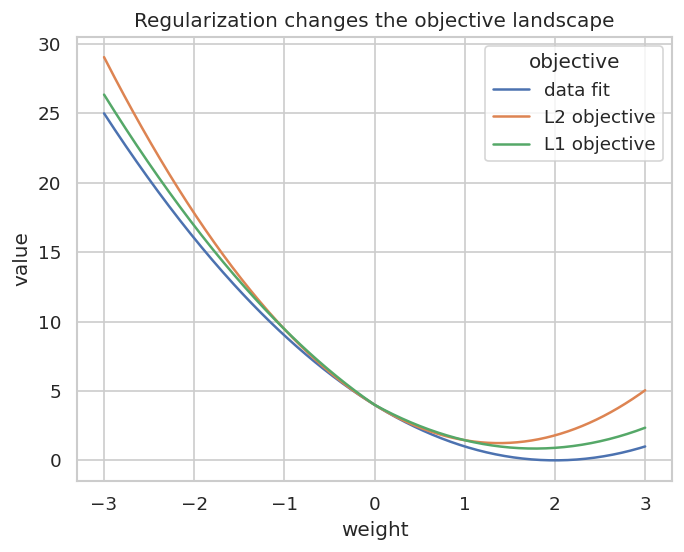

In [8]:
viz_reg_w = np.linspace(-3, 3, 301)
viz_reg_data_loss = (viz_reg_w-2.0)**2
viz_reg_lam = 0.45
viz_reg_l2 = viz_reg_data_loss + viz_reg_lam*viz_reg_w**2
viz_reg_l1 = viz_reg_data_loss + viz_reg_lam*np.abs(viz_reg_w)
viz_reg_df = pd.DataFrame({"weight": viz_reg_w, "data fit": viz_reg_data_loss, "L2 objective": viz_reg_l2, "L1 objective": viz_reg_l1}).melt(id_vars="weight", var_name="objective", value_name="value")
sns.lineplot(data=viz_reg_df, x="weight", y="value", hue="objective")
plt.title("Regularization changes the objective landscape"); plt.show()
display(pd.DataFrame({"objective": ["data fit", "data fit + L2", "data fit + L1"], "minimum value": [viz_reg_data_loss.min(), viz_reg_l2.min(), viz_reg_l1.min()]}).round(3))

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Compute MSE for true=[1,3] and predicted=[2,2].

In [9]:
y = np.array([1.0, 3.0]); pred = np.array([2.0, 2.0])
print(np.mean((y-pred)**2))

1.0


### Exercise 2
Exercise 2: Why does a Gaussian prior on weights lead to L2 regularization?

In [10]:
# The negative log of a zero-mean Gaussian prior is proportional to the sum of squared weights.

## Key takeaways
- MLE fits parameters by maximizing data likelihood; MAP also includes prior information.
- MSE corresponds to Gaussian noise; binary cross-entropy corresponds to Bernoulli likelihood.
- Regularization can be interpreted as a prior, but scaling depends on the probabilistic assumptions.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.